# predicting customer purchase behaviour

Compare four classifiers and see which session features are useful for identifying purchases. I'll use training cross-validation for model selection and leave the test set for final evaluation.

In [6]:
import hashlib
import sys
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

data_dir = Path("data")
results_dir = Path("results")
data_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid")

print("python", sys.version)
print("pandas", pd.__version__, "scikit-learn",sklearn.__version__)


python 3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]
pandas 3.1.1 scikit-learn 1.9.1


## fetching data

In [7]:
csv_path = data_dir / "online_shoppers_intention.csv"
url = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"
if not csv_path.exists():
    with urlopen(url, timeout=60) as response:
        downloaded = response.read()
    with ZipFile(BytesIO(downloaded)) as archive:
        csv_path.write_bytes(archive.read("online_shoppers_intention.csv"))

print("SHA256", hashlib.sha256(csv_path.read_bytes()).hexdigest())
df = pd.read_csv(csv_path)
raw_rows = len(df)
print("Shape", df.shape)
display(df.head())


SHA256 b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9
Shape (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## checking and preparing the data

I checked types, missing values, and duplicates before splitting the data. I removed duplicate rows so identical rows can't appear on both sides of the split (note: matching rows aren't necessarily bad records)

In [ ]:
#checking dataset

df.shape
df.info()
df.describe()
df.isnull().sum()
df["Revenue"].value_counts()

expected = {"Administrative", "Administrative_Duration", "Informational",
            "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
            "BounceRates", "ExitRates", "PageValues", "SpecialDay", "Month",
            "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType",
            "Weekend", "Revenue"}
assert set(df.columns) == expected, "check dataset columns"

for col in ["Revenue", "Weekend"]:
    values = df[col].astype(str).str.strip().str.lower()
    values = values.map({
        "true": 1,
        "false": 0,
        "1": 1,
        "0": 0
    })

    assert values.notna().all(), f"check the values in {col}"
    df[col] = values.astype(int)

print("before removing duplicates", df.shape)
print("duplicate rows", df.duplicated().sum())
duplicate_count = df.duplicated().sum()

df = df.drop_duplicates()

print("after removing duplicates", df.shape)


<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

## data split

keeping 20% for the final test (plots and model comparisons use the development portion only)

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split

X = df.drop(columns="Revenue")
y = df["Revenue"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
train_df = X_train.copy()
train_df["Revenue"] = y_train


print("development rows", len(X_train))
print("test rows", len(X_test))

display(y_train.value_counts(normalize=True).rename("training proportion"))

checks = pd.DataFrame({
    "raw_rows": [raw_rows], "duplicates_removed": [duplicate_count],
    "retained_rows": [len(df)], "development_rows": [len(X_train)], "test_rows": [len(X_test)], "development_purchase_rate": [y_train.mean()]})

checks.to_csv(results_dir / "data_checks.csv", index=False)
train_df.describe()


development rows 9764
test rows 2441


Revenue
0    0.843712
1    0.156288
Name: training proportion, dtype: float64

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue
count,9764.000000,9764.000000,9764.000000,9764.000000,9764.000000,9764.000000,9764.000000,9764.000000,9764.000000,9764.000000,9764.000000,9764.000000,9764.000000,9764.000000,9764.000000,9764.000000
mean,2.342687,82.219938,0.510344,34.950623,32.101803,1207.264687,0.020296,0.041469,5.945606,0.062351,2.130582,2.371876,3.134986,4.059402,0.233921,0.156288
std,3.349268,179.502363,1.282728,143.828323,44.817312,1926.389159,0.045234,0.046145,18.860076,0.199959,0.909649,1.734820,2.389418,4.026181,0.423344,0.363147
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.466667,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000,0.000000,0.000000
50%,1.000000,9.000000,0.000000,0.000000,18.000000,617.000000,0.002857,0.025000,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000,0.000000,0.000000
75%,4.000000,94.725000,0.000000,0.000000,39.000000,1483.650000,0.016667,0.049242,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000,0.000000,0.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000,1.000000,1.000000


## exploring the training data

I looked at class balance, feature distributions, and category purchase rates. Outliers are hidden in the box plots to make them easier to read, but not removed from the data

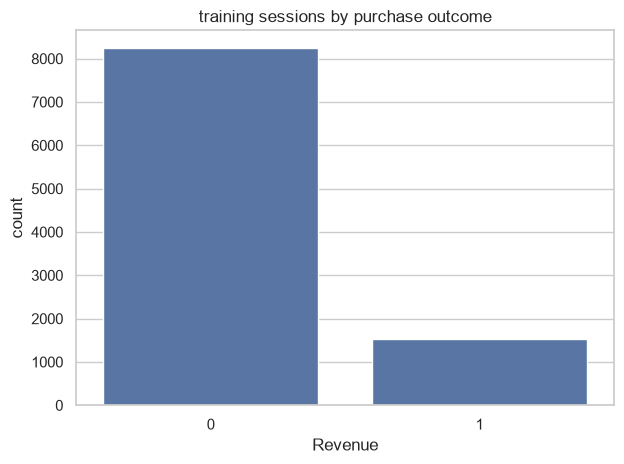

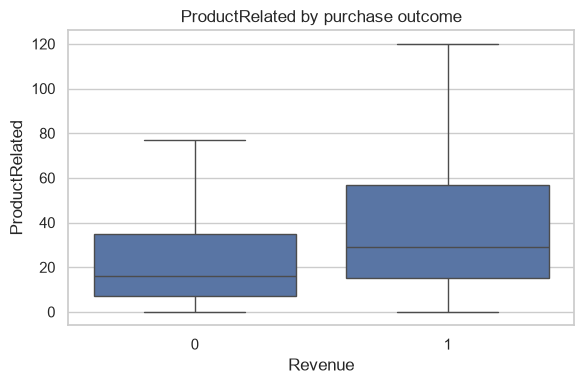

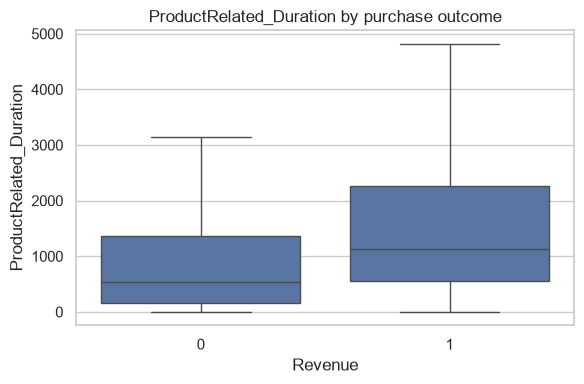

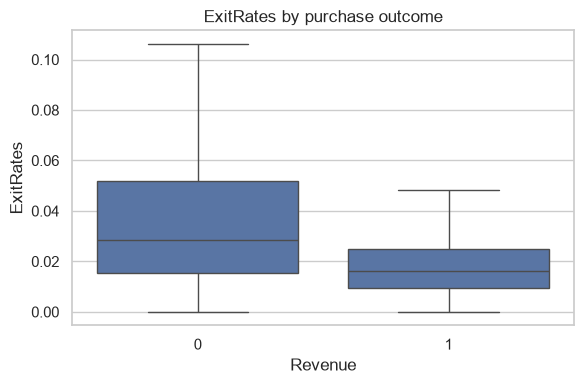

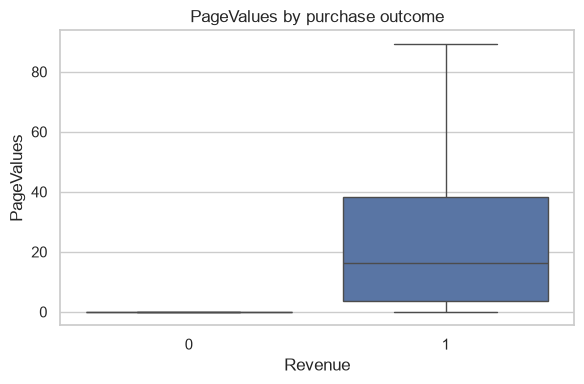

,count,purchase_rate
VisitorType,,
New_Visitor,1349,0.240919
Other,68,0.235294
Returning_Visitor,8347,0.141967


,count,purchase_rate
Month,,
Aug,360,0.172222
Dec,1363,0.131328
Feb,144,0.020833
Jul,353,0.144476
June,225,0.102222
Mar,1500,0.106000
May,2674,0.106956
Nov,2358,0.254029
Oct,433,0.224018


,count,purchase_rate
Weekend,,
0,7480,0.150668
1,2284,0.174694


<Figure size 1000x700 with 0 Axes>

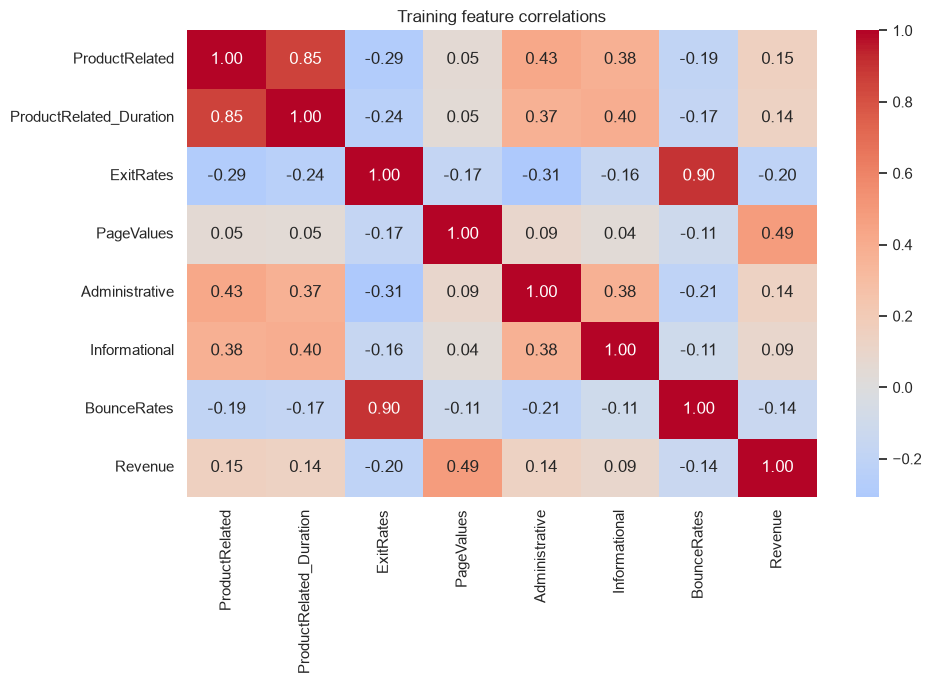

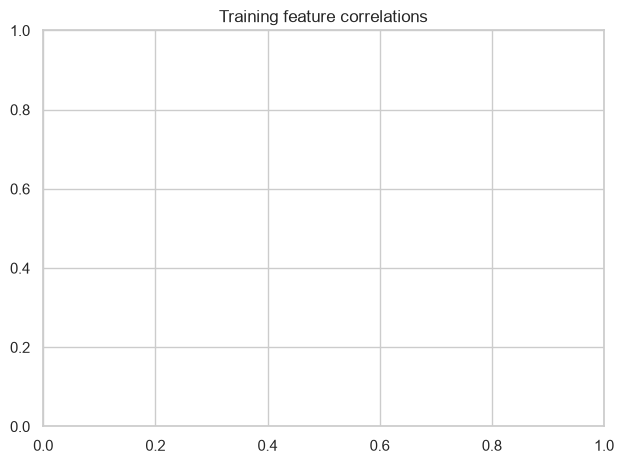

In [ ]:
sns.countplot(data=train_df, x="Revenue")
plt.title("training sessions by purchase outcome")
plt.tight_layout()
plt.savefig(results_dir / "class_balance.png", dpi=150)
plt.show()

features = ["ProductRelated", "ProductRelated_Duration", "ExitRates", "PageValues"]
plot_columns = [
    "ProductRelated",
    "ProductRelated_Duration",
    "ExitRates",
    "PageValues"
]

for column in plot_columns:
    plt.figure(figsize=(6, 4))
    sns.boxplot(
        data=train_df,
        x="Revenue",
        y=column,
        showfliers=False
    )
    plt.title(f"{column} by purchase outcome")
    plt.tight_layout()
    plt.savefig(results_dir / f"{column}_boxplot.png", dpi=150)
    plt.show()

for feature in ["VisitorType", "Month", "Weekend"]:
    rates = train_df.groupby(feature)["Revenue"].agg(["count", "mean"])
    rates = rates.rename(columns={"mean": "purchase_rate"})
    display(rates)
    rates.to_csv(results_dir / f"purchase_rates_{feature}.csv")

corr_columns = features + ["Administrative", "Informational", "BounceRates", "Revenue"]
plt.figure(figsize=(10, 7))
correlation = train_df[corr_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Training feature correlations")
plt.tight_layout()
plt.show()
plt.title("Training feature correlations")
plt.tight_layout()
plt.savefig(results_dir / "correlations.png", dpi=150)
plt.show()

### Observations

- Class balance: purchase sessions are about 15.63% of development data, compared to 84.37% non-purchase sessions, so accuracy alone wouldn't show how well models identify purchases

- Product-page activity: purchase sessions have higher median product-page counts and product-related browsing duration than non-purchase sessions (although distributions overlap)

- Exit behaviour: purchase sessions generally have lower exit rates, with lower median and narrower IQR than non-purchase sessions

- Page values: purchase sessions generally have higher PageValues, while non-purchase distribution is concentrated around 0

- Visitor types: new visitors purchase rate is 24.09%, compared to 14.20% for returning visitors, the Other category has 23.53% purchase rate but has only 68 sessions

- Month: November has the highest purchase rate at 25.40%, followed by October at 22.40%. February has the lowest rate at 2.08%

- Distributions: product-page counts, product-related browsing duration, and PageValues are strongly right-skewed, with most sessions concentrated at lower values and small numbers of larger observations

- Correlations: PageValues has the strongest positive correlation with Revenue (at least among the plotted features) at 0.49, while ExitRates has negative correlation of -0.20

- Related predictors: ProductRelated and ProductRelated_Duration are strongly correlated (0.85), and BounceRates and ExitRates too (0.90)

## preparing the model inputs

OS, browser, region, and traffic codes are categories. I'll one-hot encode them with month and visitor type. Counts and other numeric measurements are standardised, Weekend stays as 0/1. The pipeline fits preprocessing only on each training fold

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

categories = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]

def prepare_columns(columns):
    numbers = [col for col in columns if col not in categories + ["Weekend"]]
    numeric_steps = Pipeline([
        ("missing", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ])
    category_steps = Pipeline([
        ("missing", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("numbers", numeric_steps, numbers),
        ("categories", category_steps, categories),
        ("Weekend", "passthrough", ["Weekend"])
    ])


## initial model comparison

These are starting settings, I'll compare few settings later using the same training folds. F1, precision, and recall refer to the purchase class.

Also, I'm repeating the comparison without PageValues to check how much the results depend on it.

In [12]:
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Decision tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Random forest": RandomForestClassifier(n_estimators=150, min_samples_leaf=2,
                                            random_state=SEED, n_jobs=1)
}

from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score

metrics = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []

for scenario in ["all features", "without PageValues"]:
    columns = list(X_train.columns)
    if scenario == "without PageValues":
        columns.remove("PageValues")
        
    for name, model in models.items():
        pipeline = Pipeline([("prepare", prepare_columns(columns)), ("model", model)])
        scores = cross_validate(pipeline, X_train[columns], y_train, cv=cv, scoring=metrics, error_score="raise")
        row = {"scenario": scenario, "model": name}
        
        for metric in metrics:
            row[metric] = scores[f"test_{metric}"].mean()
            row[f"{metric}_sd"] = scores[f"test_{metric}"].std(ddof=1)
        rows.append(row)
        print("finished: ", scenario, name)

results = pd.DataFrame(rows).sort_values(["scenario", "f1"], ascending=[True, False])
results.to_csv(results_dir / "initial_cv_results.csv", index=False)
display(results.round(4))


finished:  all features Majority baseline
finished:  all features Logistic regression
finished:  all features Decision tree
finished:  all features KNN
finished:  all features Random forest
finished:  without PageValues Majority baseline
finished:  without PageValues Logistic regression
finished:  without PageValues Decision tree
finished:  without PageValues KNN
finished:  without PageValues Random forest


,scenario,model,accuracy,accuracy_sd,precision,precision_sd,recall,recall_sd,f1,f1_sd,roc_auc,roc_auc_sd
2,all features,Decision tree,0.8992,0.0085,0.7244,0.0226,0.5728,0.0596,0.6386,0.0420,0.9122,0.0105
4,all features,Random forest,0.9029,0.0025,0.7821,0.0159,0.5256,0.0171,0.6284,0.0118,0.9255,0.0037
1,all features,Logistic regression,0.8815,0.0054,0.7415,0.0339,0.3715,0.0308,0.4945,0.0310,0.8886,0.0140
3,all features,KNN,0.8765,0.0038,0.7390,0.0422,0.3270,0.0276,0.4523,0.0248,0.8293,0.0164
0,all features,Majority baseline,0.8437,0.0002,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000
7,without PageValues,Decision tree,0.8407,0.0044,0.4478,0.0800,0.0813,0.0300,0.1362,0.0448,0.7411,0.0174
9,without PageValues,Random forest,0.8472,0.0031,0.6032,0.0874,0.0662,0.0122,0.1191,0.0211,0.7714,0.0172
8,without PageValues,KNN,0.8400,0.0041,0.4261,0.0772,0.0590,0.0127,0.1030,0.0204,0.6952,0.0242
6,without PageValues,Logistic regression,0.8432,0.0016,0.4850,0.0808,0.0315,0.0037,0.0590,0.0066,0.7434,0.0252
5,without PageValues,Majority baseline,0.8437,0.0002,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000


majority baseline predicts no purchases, so its purchase precision, recall, and F1 are 0. Fold standard deviations are variability across folds and not statistical significance.

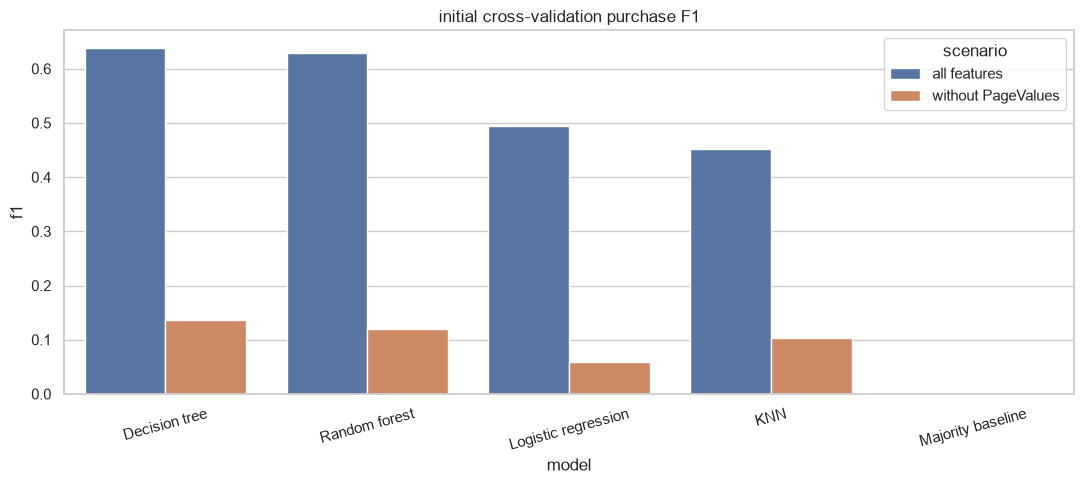

In [13]:
plt.figure(figsize=(11, 5))
sns.barplot(data=results, x="model", y="f1", hue="scenario", errorbar=None)
plt.title("initial cross-validation purchase F1")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(results_dir / "cv_f1_comparison.png", dpi=150)
plt.show()


### Model observations

- Best development F1: Decision Tree had highest mean purchase-class F1 of 0.6386 +- 0.042 using all features, compared with 0.6284 +- 0.0118 for Random Forest

- Precision and recall tradeoff: DT had precision of 0.7244 and recall of 0.5728, while RF had higher precision of 0.7821 but lower recall of 0.5256

- Other performance measures: RF achieved highest accuracy at 0.9029 and ROC-AUC at 0.9255 (when all features were included)

- Majority baseline: majority classifier got accuracy of 0.8437 but purchase-class precision, recall, and F1 were all 0, showing why just accuracy is insufficient

- Effect of excluding PageValues: DT F1 decreased from 0.6386 to 0.1362, while RF F1 decreased from 0.6284 to 0.1191, meaning the current models depend heavily on this

- Preliminary interpretation: DT leads on purchase-class F1, while RF has higher precision, stronger ROC-AUC, and less variation in F1 across folds

- Remaining evaluation: these are development CV results, final model selection and held-out test evaluation are still pending